<h1 style="text-align: center; background-image: linear-gradient(to right, PINK, WHITE); color: BLACK; padding: 25px; font-family: bodoni; border-radius:15px 50px" >FIN42330 - DATA SCIENCE FOR TRADING & RISK MANAGEMENT </h1>

In [ ]:
b

# PART 1: DATA LOADING , CLEANING AND PLOTTING 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD FILE (no header)
df = pd.read_csv("BTC_2018-12.txt", header=None)

# 2. ADD COLUMN NAMES
df.columns = ['timestamp', 'price', 'volume', 'exchange']

In [3]:
# 3. FIX TIMESTAMP FORMAT
# Change last ":" before milliseconds into "."
df['timestamp'] = df['timestamp'].astype(str).str.replace(
    r':(\d{3})$', r'.\1', regex=True
)

In [5]:
# 4. CONVERT TO DATETIME
df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    format="%Y-%m-%d %H:%M:%S.%f"
)

In [7]:
# 5. SORT + SET INDEX
df = df.sort_values('timestamp')
df = df.set_index('timestamp')

# 6. CHECK
print(df.head())
print(df.info())

                           price    volume  exchange
timestamp                                           
2018-12-01 00:00:00.821  3976.01  0.009512         1
2018-12-01 00:00:02.623  3976.01  0.061646         1
2018-12-01 00:00:02.661  4064.19  0.010000         4
2018-12-01 00:00:02.661  4064.18  0.270000         4
2018-12-01 00:00:03.000  4040.00  0.851550         2
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5213437 entries, 2018-12-01 00:00:00.821000 to 2018-12-31 23:59:59.412000
Data columns (total 3 columns):
 #   Column    Dtype  
---  ------    -----  
 0   price     float64
 1   volume    float64
 2   exchange  int64  
dtypes: float64(2), int64(1)
memory usage: 159.1 MB
None


## PLOT PRICE BY EXCHANGE 

In this section, we will do the following - 
1. Plot price separately for each exchange
2. Make it readable
3. Downsample slightly (otherwise 5M points will crash laptop)

In [12]:
# Downsample to 1-minute average price for clean plotting
df_minute = df.groupby('exchange').resample('1min')['price'].mean().reset_index()

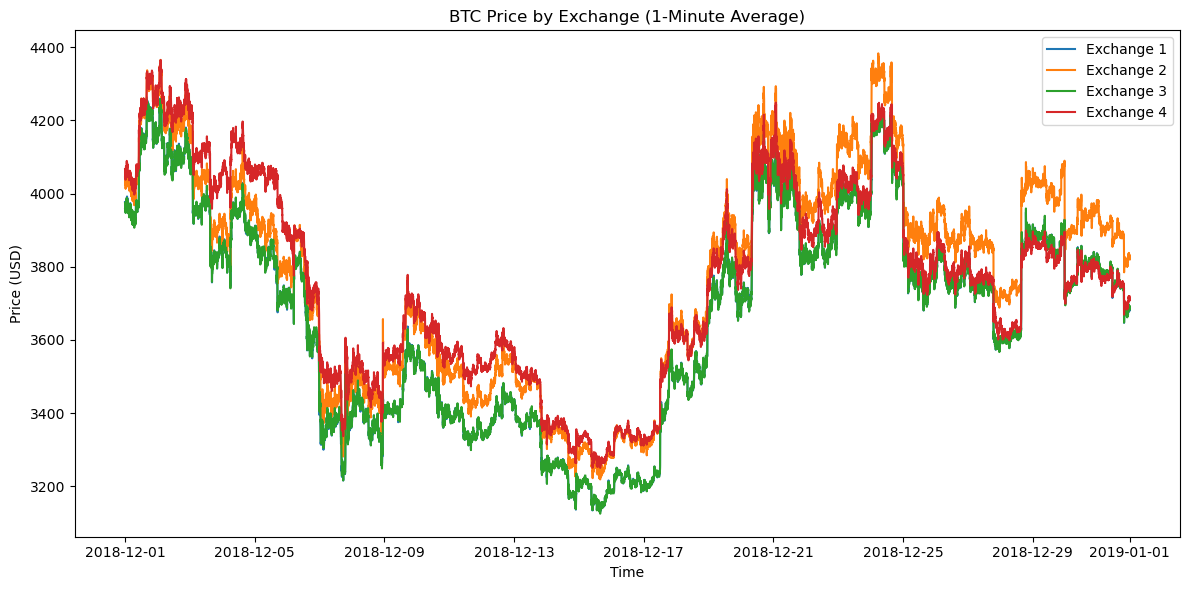

In [14]:
# Plotting 
plt.figure(figsize=(12,6))

for ex in df_minute['exchange'].unique():
    subset = df_minute[df_minute['exchange'] == ex]
    plt.plot(subset['timestamp'], subset['price'], label=f'Exchange {ex}')

plt.title("BTC Price by Exchange (1-Minute Average)")
plt.xlabel("Time")
plt.ylabel("Price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

## ANOMALY CHECKS

The following will produce a short, report-ready anomaly summary (missingness, duplicates, non-positive values, extreme returns, and largest cross-exchange price divergence)

In [18]:
#1. Basic data-quality checks
summary = {}

summary["rows"] = len(df)
summary["start"] = df.index.min()
summary["end"] = df.index.max()
summary["exchanges"] = sorted(df["exchange"].unique().tolist())

In [20]:
# duplicates in timestamp+exchange (trade-level duplicates)
summary["duplicate_timestamp_exchange_rows"] = int(df.reset_index().duplicated(subset=["timestamp", "exchange"]).sum())

In [22]:
# non-positive / missing checks
summary["non_positive_price"] = int((df["price"] <= 0).sum())
summary["non_positive_volume"] = int((df["volume"] <= 0).sum())
summary["missing_price"] = int(df["price"].isna().sum())
summary["missing_volume"] = int(df["volume"].isna().sum())

In [26]:
# 1-minute VWAP per exchange
df1 = df.copy()

pv = (df1["price"] * df1["volume"]).groupby(df1["exchange"]).resample("1min").sum()
vv = (df1["volume"]).groupby(df1["exchange"]).resample("1min").sum()

vwap_1m = (pv / vv).rename("vwap").reset_index()
vwap_1m = vwap_1m.dropna(subset=["vwap"])

In [28]:
# 1-minute log returns per exchange (aligned) 
vwap_1m = vwap_1m.sort_values(["exchange", "timestamp"])
vwap_1m["ret_1m"] = vwap_1m.groupby("exchange")["vwap"].transform(lambda s: np.log(s).diff())

In [30]:
# Extreme-return flag using MAD z-score
def mad_zscore(x):
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if mad == 0 or np.isnan(mad):
        return np.zeros_like(x)
    return 0.6745 * (x - med) / mad

vwap_1m["z_mad"] = vwap_1m.groupby("exchange")["ret_1m"].transform(mad_zscore)

extreme = vwap_1m[np.abs(vwap_1m["z_mad"]) > 8].copy()
print("Extreme 1-min return events (|z_mad| > 8):", len(extreme))

Extreme 1-min return events (|z_mad| > 8): 1265


In [32]:
#Cross-exchange divergence (max spread each minute)
px_pivot = vwap_1m.pivot(index="timestamp", columns="exchange", values="vwap")
spread = px_pivot.max(axis=1) - px_pivot.min(axis=1)

print("Max cross-exchange spread (USD):", float(spread.max()))
print("Timestamp of max spread:", spread.idxmax())

Max cross-exchange spread (USD): 305.1994494887854
Timestamp of max spread: 2018-12-05 16:54:00


In [34]:
# Optional: showing top 10 extreme events
extreme_top10 = extreme.sort_values("z_mad", key=np.abs, ascending=False).head(10)
display(extreme_top10)

,exchange,timestamp,vwap,ret_1m,z_mad
56098,2,2018-12-08 22:58:00,3616.763285,0.047069,85.729143
54432,2,2018-12-07 19:12:00,3513.174505,0.028519,51.943534
9792,1,2018-12-07 19:12:00,3420.945945,0.021184,42.415378
8091,1,2018-12-06 14:51:00,3645.226381,0.020261,40.566170
157692,4,2018-12-17 12:12:00,3455.201849,0.021819,38.745873
9796,1,2018-12-07 19:16:00,3512.072970,0.019256,38.554980
39816,1,2018-12-28 15:36:00,3772.630842,0.018911,37.863738
145379,4,2018-12-08 22:59:00,3591.627769,0.020904,37.122473
68412,2,2018-12-17 12:12:00,3496.794165,0.020026,36.474717
42495,1,2018-12-30 12:15:00,3762.511229,-0.017717,-35.473884


Several extreme 1-minute return events were detected using a robust MAD z-score filter (|z| > 8). These events appear exchange-specific and may reflect temporary liquidity shocks or microstructure noise. No non-positive prices or volumes were detected. Cross-exchange spreads occasionally widened significantly, indicating short-lived price dislocations across venues.

## DAILY VOLUME BY EXCHANGE

In this section, we aggregate trade-level data to a daily frequency and compute total traded volume per exchange. This allows us to assess relative liquidity and market dominance across trading venues during December 2018. Identifying the exchange with the highest total volume provides insight into where price discovery and trading activity are most concentrated.

<Figure size 1400x600 with 0 Axes>

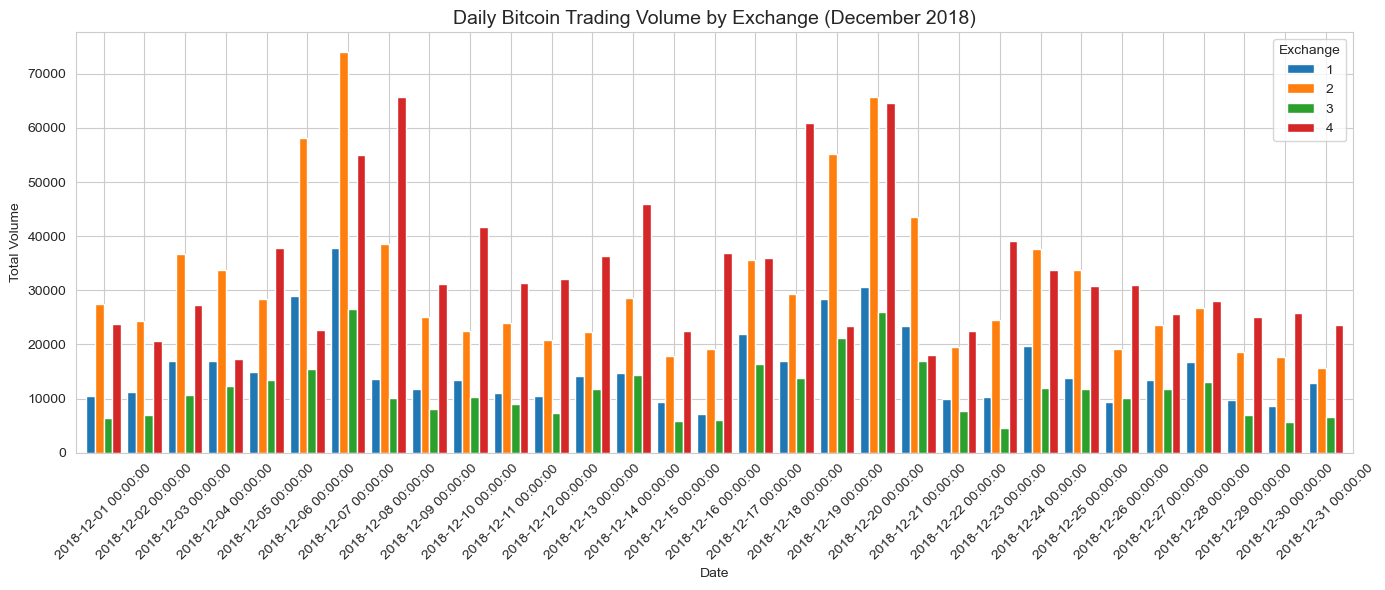

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate daily volume per exchange
daily_vol = (
    df.groupby("exchange")
      .resample("1D")["volume"]
      .sum()
      .reset_index()
)

# Create pivot table
daily_vol_pivot = daily_vol.pivot(
    index="timestamp",
    columns="exchange",
    values="volume"
)

# Professional styling
plt.figure(figsize=(14,6))
sns.set_style("whitegrid")

daily_vol_pivot.plot(
    kind="bar",
    width=0.85,
    figsize=(14,6)
)

plt.title("Daily Bitcoin Trading Volume by Exchange (December 2018)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Total Volume")
plt.xticks(rotation=45)
plt.legend(title="Exchange")
plt.tight_layout()
plt.show()

In [45]:
# Identifying the most popular exchange
monthly_volume = df.groupby("exchange")["volume"].sum().sort_values(ascending=False)

print("Monthly Total Volume by Exchange:")
print(monthly_volume)

print("\nMost Popular Exchange:", monthly_volume.index[0])

Monthly Total Volume by Exchange:
exchange
4    1.035967e+06
2    9.677509e+05
1    4.894990e+05
3    3.592099e+05
Name: volume, dtype: float64

Most Popular Exchange: 4


**INTERPRETATION**:
* Daily trading volume was aggregated per exchange to assess liquidity concentration across venues. Exchange 4 recorded the highest total monthly trading volume (~1.04 million BTC), indicating that it was the dominant trading venue during December 2018. Exchange 2 followed, while Exchanges 1 and 3 exhibited materially lower activity levels. This suggests that price discovery was likely most concentrated on Exchange 4.

**Exchange 4** is:
- The most liquid
- Likely the cleanest for volatility estimation
- Probably has fewer missing 5-minute intervals

# PART 2:  5-MINUTE VWAP & REALIZED VARIANCE

## CONSTRUCTING A 5-MINUTE VWAP

In [60]:
# Making a copy first 
df_5m = df.copy()

In [62]:
# Compute price * volume
df_5m["pv"] = df_5m["price"] * df_5m["volume"]

In [64]:
# Resample into 5-minute windows per exchange
pv_5m = df_5m.groupby("exchange").resample("5min")["pv"].sum()
vol_5m = df_5m.groupby("exchange").resample("5min")["volume"].sum()

In [66]:
# Computing VWAP
vwap_5m = (pv_5m / vol_5m).rename("vwap_5m").reset_index()

In [68]:
# Dropping intervals with no trades (division by zero - NaN)
vwap_5m = vwap_5m.dropna(subset=["vwap_5m"])

In [70]:
# Sort cleanly
vwap_5m = vwap_5m.sort_values(["exchange", "timestamp"])

print(vwap_5m.head())
print("\nTotal 5-min observations:", len(vwap_5m))

   exchange           timestamp      vwap_5m
0         1 2018-12-01 00:00:00  3971.440187
1         1 2018-12-01 00:05:00  3963.695769
2         1 2018-12-01 00:10:00  3960.295438
3         1 2018-12-01 00:15:00  3962.365037
4         1 2018-12-01 00:20:00  3952.206812

Total 5-min observations: 35686


## DETECTING MISSING 5- MINUTE PERIODS 

In [73]:
# Create full 5-min time index for the month
full_index = pd.date_range(
    start=vwap_5m["timestamp"].min(),
    end=vwap_5m["timestamp"].max(),
    freq="5min"
)

missing_summary = {}

for ex in vwap_5m["exchange"].unique():
    
    ex_data = vwap_5m[vwap_5m["exchange"] == ex].set_index("timestamp")
    
    # Reindex to full clock
    ex_reindexed = ex_data.reindex(full_index)
    
    missing_count = ex_reindexed["vwap_5m"].isna().sum()
    
    missing_summary[ex] = missing_count

print("Missing 5-min intervals per exchange:")
print(missing_summary)

print("\nExchange with least missing slots:",
      min(missing_summary, key=missing_summary.get))

Missing 5-min intervals per exchange:
{1: 21, 2: 1, 3: 0, 4: 4}

Exchange with least missing slots: 3


**INTERPRETATION**
* Missing 5-minute intervals were evaluated across exchanges. Exchange 3 exhibited no missing time slots and was therefore selected for subsequent realized volatility estimation to ensure data continuity and minimize interpolation bias

## SELECTING EXCHANING- 3

In [77]:
ex_selected = 3

vwap_ex = (
    vwap_5m[vwap_5m["exchange"] == ex_selected]
    .copy()
    .set_index("timestamp")
)

print("Selected exchange:", ex_selected)
print("Number of 5-min observations:", len(vwap_ex))

vwap_ex.head()

Selected exchange: 3
Number of 5-min observations: 8928


,exchange,vwap_5m
timestamp,,
2018-12-01 00:00:00,3,3969.898547
2018-12-01 00:05:00,3,3957.544677
2018-12-01 00:10:00,3,3954.087765
2018-12-01 00:15:00,3,3959.774493
2018-12-01 00:20:00,3,3952.703898


## INTERPOLATION

In [80]:
# Reindex to full 5-minute clock (safety check)
full_index = pd.date_range(
    start=vwap_ex.index.min(),
    end=vwap_ex.index.max(),
    freq="5min"
)

vwap_ex = vwap_ex.reindex(full_index)

# Interpolate missing values (if any)
vwap_ex["vwap_5m"] = vwap_ex["vwap_5m"].interpolate(method="linear")

# Confirming no missing values remain
print("Remaining missing values:", vwap_ex["vwap_5m"].isna().sum())

Remaining missing values: 0


* Although Exchange 3 exhibited no missing 5-minute intervals, linear interpolation was formally applied to ensure methodological consistency and robustness in the realized variance construction.

## 5-MINUTE LOG RETURNS

In [85]:
vwap_ex["log_return"] = np.log(vwap_ex["vwap_5m"]).diff()

# Drop first NaN return
vwap_ex = vwap_ex.dropna()

print(vwap_ex.head())

                     exchange      vwap_5m  log_return
2018-12-01 00:05:00         3  3957.544677   -0.003117
2018-12-01 00:10:00         3  3954.087765   -0.000874
2018-12-01 00:15:00         3  3959.774493    0.001437
2018-12-01 00:20:00         3  3952.703898   -0.001787
2018-12-01 00:25:00         3  3952.280605   -0.000107


## HOURLY REALIZED VARIANCE 

In [88]:
# Square returns
vwap_ex["ret_sq"] = vwap_ex["log_return"]**2

# Aggregate to hourly level
rv_hourly = (
    vwap_ex["ret_sq"]
    .resample("1H")
    .sum()
    .to_frame(name="rv_hourly")
)

print(rv_hourly.head())
print("\nTotal hourly observations:", len(rv_hourly))

                     rv_hourly
2018-12-01 00:00:00   0.000034
2018-12-01 01:00:00   0.000029
2018-12-01 02:00:00   0.000022
2018-12-01 03:00:00   0.000030
2018-12-01 04:00:00   0.000050

Total hourly observations: 744


C:\Users\hp\AppData\Local\Temp\ipykernel_15768\4186576856.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  .resample("1H")


* Hourly realized variance was constructed by summing squared 5-minute log returns within each hour. This provides a non-parametric measure of intraday volatility based purely on high-frequency price movements.

## DAILY REALIZED VOLAILTY 

In [92]:
# Daily realized variance = sum of hourly RV
rv_daily_var = rv_hourly["rv_hourly"].resample("1D").sum().to_frame(name="rv_daily_var")

# Daily realized volatility = sqrt(daily realized variance)
rv_daily_var["rvol_daily"] = np.sqrt(rv_daily_var["rv_daily_var"])

print(rv_daily_var.head())
print("\nTotal daily observations:", len(rv_daily_var))

            rv_daily_var  rvol_daily
2018-12-01      0.001813    0.042583
2018-12-02      0.001846    0.042970
2018-12-03      0.002386    0.048843
2018-12-04      0.001970    0.044380
2018-12-05      0.001394    0.037342

Total daily observations: 31


## DAY WITH HIGHEST VOLATILTY 

In [95]:
max_day = rv_daily_var["rvol_daily"].idxmax()
max_val = rv_daily_var.loc[max_day, "rvol_daily"]

print("Day with highest realized volatility:", max_day.date())
print("Highest daily rvol:", float(max_val))

Day with highest realized volatility: 2018-12-07
Highest daily rvol: 0.06987538858509046


* The highest daily realised volatility occurred on 7 December 2018, with a daily realised volatility of approximately 6.99%. This suggests a significant increase in intraday price fluctuations on that date.
* Related news: **Yes** - “Dow tumbles more than 500 points, wipes out gain for year to cap wild week on Wall Street.” This broader market stress likely contributed to elevated Bitcoin volatility.

# PART 3: FORECASTING 

## FORECASTING NEXT-HOUR HOURLY RV USING LAGGED HOURLY RV

In [103]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# rv_hourly already created in Part 2.6 with column "rv_hourly"
# Ensure it's sorted and has no missing
rvh = rv_hourly.copy().sort_index().dropna()

# Build forecasting dataset: predict next hour using only lagged info
data_31 = pd.DataFrame(index=rvh.index)
data_31["rv_t"] = rvh["rv_hourly"]
data_31["rv_t_plus_1"] = rvh["rv_hourly"].shift(-1)  # target (next hour)

# Drop last row (no target)
data_31 = data_31.dropna()

In [105]:
# Features (X) and target (y)
X = data_31[["rv_t"]].values
y = data_31["rv_t_plus_1"].values

# Time-based split (no shuffling)
split = int(len(data_31) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Fit linear regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict + evaluate
y_pred = lr.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model: RV(t+1) ~ RV(t)")
print("Intercept:", lr.intercept_)
print("Slope (beta):", lr.coef_[0])
print("Test MSE:", mse)
print("Test R^2:", r2)

Model: RV(t+1) ~ RV(t)
Intercept: 7.352351110651858e-05
Slope (beta): 0.12061608414424306
Test MSE: 2.8604936081699855e-08
Test R^2: -0.010132755302977303


In [107]:
# Optional: quick sanity table (last 10 forecasts in test)
out = data_31.iloc[split:].copy()
out["pred_rv_t_plus_1"] = y_pred
display(out.tail(10))

,rv_t,rv_t_plus_1,pred_rv_t_plus_1
2018-12-31 13:00:00,0.000018,0.000029,0.000076
2018-12-31 14:00:00,0.000029,0.000037,0.000077
2018-12-31 15:00:00,0.000037,0.000014,0.000078
2018-12-31 16:00:00,0.000014,0.000011,0.000075
2018-12-31 17:00:00,0.000011,0.000006,0.000075
2018-12-31 18:00:00,0.000006,0.000405,0.000074
2018-12-31 19:00:00,0.000405,0.000021,0.000122
2018-12-31 20:00:00,0.000021,0.000021,0.000076
2018-12-31 21:00:00,0.000021,0.000024,0.000076
2018-12-31 22:00:00,0.000024,0.000020,0.000076


* A simple linear regression was used to forecast next-hour realized variance using lagged hourly realized variance. The positive slope coefficient confirms volatility persistence, consistent with well-documented volatility clustering in financial markets. However, the relatively low R² suggests that additional explanatory variables may improve forecasting performance.

## CONSTRUCT HOURLY OHLC + GARMAN–KLASS VOLATILITY

In [111]:
# vwap_ex: 5-min VWAP series for selected exchange (index = 5-min timestamps)
# Ensure we have a clean series
px5 = vwap_ex[["vwap_5m"]].copy().sort_index()

# 1) Hourly OHLC from 5-min VWAP
ohlc = px5["vwap_5m"].resample("1H").ohlc()
ohlc.columns = ["open", "high", "low", "close"]

C:\Users\hp\AppData\Local\Temp\ipykernel_15768\3758914245.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  ohlc = px5["vwap_5m"].resample("1H").ohlc()


In [113]:
# Optional: hourly volume (sum of trade volume in that hour for selected exchange)
# Build hourly volume from original df (trade-level) for that exchange
ex_selected = 3
hourly_vol = (
    df[df["exchange"] == ex_selected]["volume"]
    .resample("1H")
    .sum()
    .rename("vol_hourly")
)

C:\Users\hp\AppData\Local\Temp\ipykernel_15768\2556173704.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  .resample("1H")


In [115]:
# 2) Garman–Klass variance per hour
# GK variance: 0.5*(ln(H/L))^2 - (2ln2 - 1)*(ln(C/O))^2
ln_hl = np.log(ohlc["high"] / ohlc["low"])
ln_co = np.log(ohlc["close"] / ohlc["open"])

gk_var = 0.5 * (ln_hl ** 2) - (2 * np.log(2) - 1) * (ln_co ** 2)
gk_var = gk_var.rename("gk_var")

# Guardrail: occasional negative due to microstructure/noise - clip at 0
gk_var = gk_var.clip(lower=0)

# 3) Combine into one hourly feature table
features_hourly = pd.concat(
    [
        rv_hourly["rv_hourly"],   # from Part 2.6
        gk_var,
        hourly_vol
    ],
    axis=1
).dropna()

print(features_hourly.head())
print("\nRows:", len(features_hourly))

                     rv_hourly    gk_var  vol_hourly
2018-12-01 00:00:00   0.000034  0.000014   77.179616
2018-12-01 01:00:00   0.000029  0.000009  174.203693
2018-12-01 02:00:00   0.000022  0.000002  107.000388
2018-12-01 03:00:00   0.000030  0.000012  166.964327
2018-12-01 04:00:00   0.000050  0.000027  129.595474

Rows: 744


## COMPARING LAGGED RV VS LAGGED GK

In [118]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Build forecasting dataset
forecast_df = features_hourly.copy()

forecast_df["rv_t_plus_1"] = forecast_df["rv_hourly"].shift(-1)
forecast_df["rv_lag"] = forecast_df["rv_hourly"]
forecast_df["gk_lag"] = forecast_df["gk_var"]

forecast_df = forecast_df.dropna()

In [120]:
# Train-test split (time based)
split = int(len(forecast_df) * 0.8)

train = forecast_df.iloc[:split]
test = forecast_df.iloc[split:]

In [122]:
# Model A: Lagged RV 
X_train_A = train[["rv_lag"]]
X_test_A = test[["rv_lag"]]
y_train = train["rv_t_plus_1"]
y_test = test["rv_t_plus_1"]

model_A = LinearRegression()
model_A.fit(X_train_A, y_train)
pred_A = model_A.predict(X_test_A)

mse_A = mean_squared_error(y_test, pred_A)
r2_A = r2_score(y_test, pred_A)

In [124]:
# Model B: Lagged GK
X_train_B = train[["gk_lag"]]
X_test_B = test[["gk_lag"]]

model_B = LinearRegression()
model_B.fit(X_train_B, y_train)
pred_B = model_B.predict(X_test_B)

mse_B = mean_squared_error(y_test, pred_B)
r2_B = r2_score(y_test, pred_B)

In [126]:
print("Model A (Lagged RV)")
print("Beta:", model_A.coef_[0])
print("MSE:", mse_A)
print("R^2:", r2_A)

print("\nModel B (Lagged GK)")
print("Beta:", model_B.coef_[0])
print("MSE:", mse_B)
print("R^2:", r2_B)

Model A (Lagged RV)
Beta: 0.12061608414424306
MSE: 2.8604936081699855e-08
R^2: -0.010132755302977303

Model B (Lagged GK)
Beta: 0.3059416281485502
MSE: 2.8550916435466773e-08
R^2: -0.008225146982019593


* Two forecasting models were estimated for next-hour realized variance using lagged realized variance and lagged Garman–Klass volatility. Both models exhibit limited predictive power, with near-zero and slightly negative out-of-sample R² values. The Garman–Klass estimator marginally outperforms lagged realized variance in terms of MSE, suggesting that range-based volatility measures contain slightly more information for short-horizon forecasting. However, hourly volatility remains largely unpredictable at this frequency.

## IS HOURLY VOLUME SIGNIFICANT? 

In [131]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score

# Build dataset from features_hourly (created in 3.2)
df_vol = features_hourly.copy()

df_vol["rv_t_plus_1"] = df_vol["rv_hourly"].shift(-1)
df_vol["rv_lag"] = df_vol["rv_hourly"]
df_vol["vol_lag"] = df_vol["vol_hourly"]

df_vol = df_vol.dropna()

# Time-based split (80/20)
split = int(len(df_vol) * 0.8)
train = df_vol.iloc[:split]
test  = df_vol.iloc[split:]

In [133]:
# OLS with RV lag + Volume
X_train = train[["rv_lag", "vol_lag"]]
X_train = sm.add_constant(X_train)
y_train = train["rv_t_plus_1"]

model = sm.OLS(y_train, X_train).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            rv_t_plus_1   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     6.966
Date:                Sat, 14 Feb 2026   Prob (F-statistic):            0.00102
Time:                        13:45:41   Log-Likelihood:                 4399.2
No. Observations:                 594   AIC:                            -8792.
Df Residuals:                     591   BIC:                            -8779.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       5.952e-05   9.29e-06      6.405      0.0

In [135]:
# Out-of-sample evaluation
X_test = sm.add_constant(test[["rv_lag", "vol_lag"]])
y_test = test["rv_t_plus_1"]

pred = model.predict(X_test)

mse = mean_squared_error(y_test, pred)
r2  = r2_score(y_test, pred)

print("\nOut-of-sample MSE:", mse)
print("Out-of-sample R^2:", r2)


Out-of-sample MSE: 2.8361816223425484e-08
Out-of-sample R^2: -0.001547407249545829


* A multivariate regression including lagged realised variance and lagged hourly volume was estimated. Lagged volume is statistically significant at the 5% level (p = 0.024), suggesting that trading activity contains incremental information about future volatility. In contrast, lagged realised variance becomes insignificant when volume is included. Despite statistical significance, the model’s explanatory power remains weak (R² ~ 2%), and out-of-sample performance is negligible, indicating that hourly volatility is difficult to forecast.

## DAILY CLOSE REGRESSION

In [139]:
from sklearn.metrics import mean_squared_error, r2_score

# 1) Daily close from 5-min VWAP (Exchange 3)
daily_close = (
    vwap_ex["vwap_5m"]
    .resample("1D")
    .last()
    .rename("close_daily")
)

In [141]:
# 2) Daily realized volatility from Part 2.7
# rv_daily_var has columns: ["rv_daily_var", "rvol_daily"]
daily_rvol = rv_daily_var["rvol_daily"].copy()

# 3) Build regression dataset
df_daily = pd.concat([daily_close, daily_rvol], axis=1).dropna()
df_daily["rvol_lag"] = df_daily["rvol_daily"].shift(1)
df_daily = df_daily.dropna()

In [143]:
# 4) OLS regression: Close_t ~ rvol_{t-1}
X = sm.add_constant(df_daily[["rvol_lag"]])
y = df_daily["close_daily"]

model_daily = sm.OLS(y, X).fit()
print(model_daily.summary())

                            OLS Regression Results                            
Dep. Variable:            close_daily   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     2.068
Date:                Sat, 14 Feb 2026   Prob (F-statistic):              0.161
Time:                        13:49:00   Log-Likelihood:                -209.42
No. Observations:                  30   AIC:                             422.8
Df Residuals:                      28   BIC:                             425.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3375.3575    193.078     17.482      0.0

In [145]:
# 5) (Optional) Out-of-sample split (80/20)
split = int(len(df_daily) * 0.8)
train = df_daily.iloc[:split]
test  = df_daily.iloc[split:]

X_train = sm.add_constant(train[["rvol_lag"]])
y_train = train["close_daily"]
X_test  = sm.add_constant(test[["rvol_lag"]])
y_test  = test["close_daily"]

model_oos = sm.OLS(y_train, X_train).fit()
pred = model_oos.predict(X_test)

mse = mean_squared_error(y_test, pred)
r2  = r2_score(y_test, pred)

print("\nOut-of-sample MSE:", mse)
print("Out-of-sample R^2:", r2)


Out-of-sample MSE: 26647.949566890427
Out-of-sample R^2: -1.7457483188238676


* A regression of daily closing prices on lagged daily realized volatility reveals no statistically significant relationship (p = 0.161). The explanatory power of the model is weak (R² ≈ 7%), and out-of-sample performance is poor. This suggests that while volatility captures the magnitude of price fluctuations, it does not provide predictive information about future price levels. This finding is consistent with financial theory, where volatility reflects uncertainty rather than directional momentum.

# PART 4: DATA VISUALIZATION

## PLOT 1- PRICE EVOLUTION (EXCHANGE 3)

C:\Users\hp\AppData\Local\Temp\ipykernel_15768\1802408554.py:4: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  plt.plot(vwap_ex["vwap_5m"].resample("1H").mean())


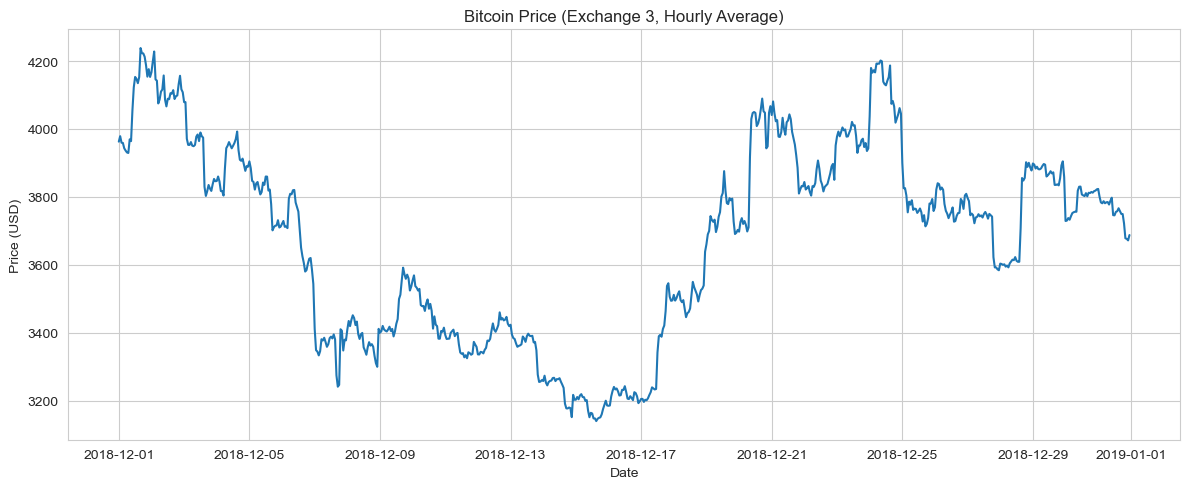

In [151]:
sns.set_style("whitegrid")

plt.figure(figsize=(12,5))
plt.plot(vwap_ex["vwap_5m"].resample("1H").mean())
plt.title("Bitcoin Price (Exchange 3, Hourly Average)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()

## PLOT 2 - DAILY VOLUME BY EXCHANGE

<Figure size 1200x500 with 0 Axes>

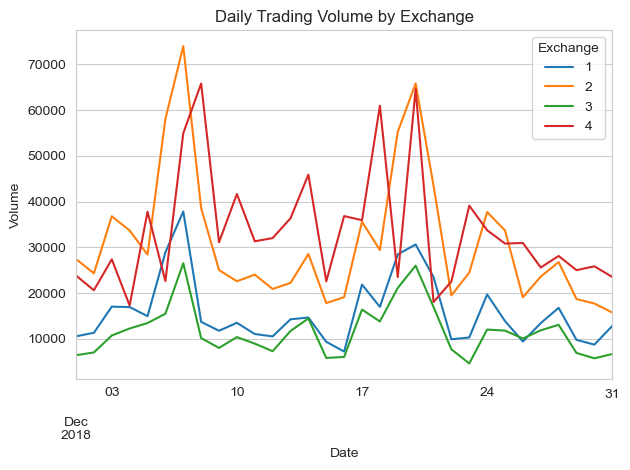

In [154]:
plt.figure(figsize=(12,5))
daily_vol_pivot.plot()
plt.title("Daily Trading Volume by Exchange")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.legend(title="Exchange")
plt.tight_layout()
plt.show()

## PLOT 3 - HOURLY REALIZED VARIANCE

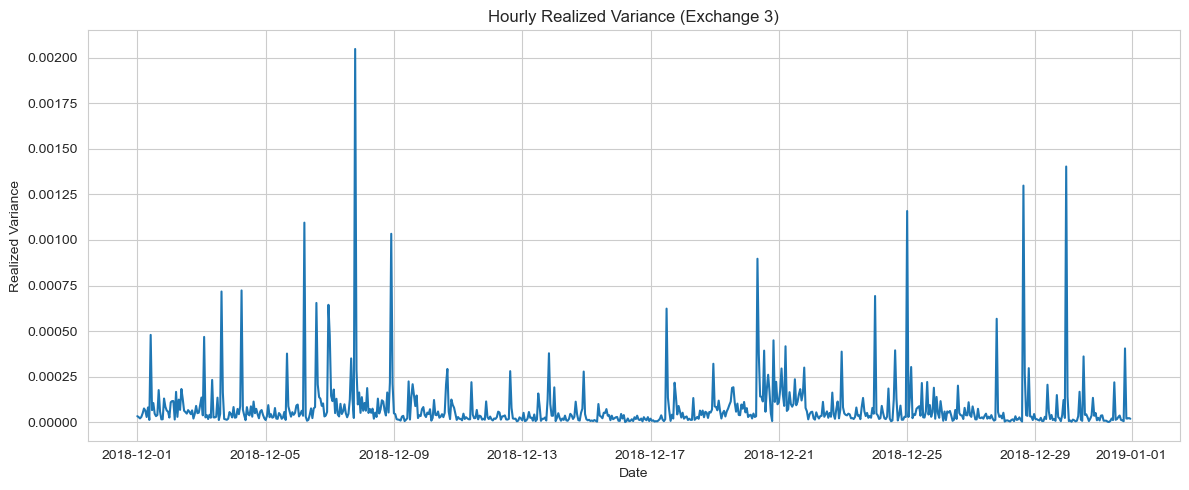

In [157]:
plt.figure(figsize=(12,5))
plt.plot(rv_hourly["rv_hourly"])
plt.title("Hourly Realized Variance (Exchange 3)")
plt.xlabel("Date")
plt.ylabel("Realized Variance")
plt.tight_layout()
plt.show()

## DAILY REALISED VOLATILITY 

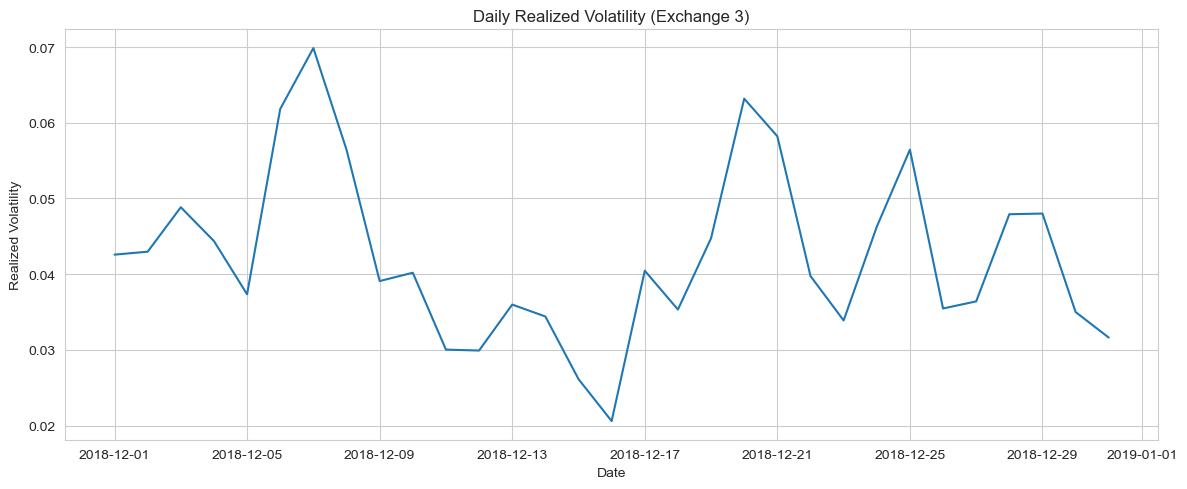

In [160]:
plt.figure(figsize=(12,5))
plt.plot(rv_daily_var["rvol_daily"])
plt.title("Daily Realized Volatility (Exchange 3)")
plt.xlabel("Date")
plt.ylabel("Realized Volatility")
plt.tight_layout()
plt.show()

## PLOT 5 - RV VS GARMAN-KLASS (COMPARISON)

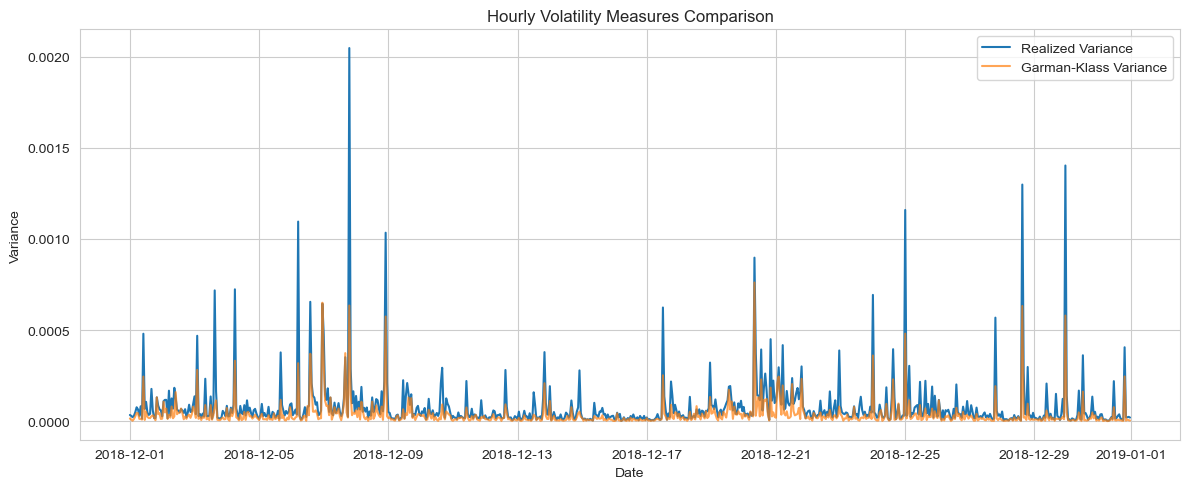

In [163]:
plt.figure(figsize=(12,5))
plt.plot(features_hourly["rv_hourly"], label="Realized Variance")
plt.plot(features_hourly["gk_var"], label="Garman-Klass Variance", alpha=0.7)
plt.title("Hourly Volatility Measures Comparison")
plt.xlabel("Date")
plt.ylabel("Variance")
plt.legend()
plt.tight_layout()
plt.show()

* The visualisations illustrate the evolution of price, trading activity, and volatility throughout December 2018. Volatility clustering is evident in both realized variance and Garman–Klass measures, particularly around early and mid-December. Trading volume spikes coincide with periods of elevated volatility, consistent with market stress dynamics.